# Planning and Learning: Dyna

This notebook implements the Dyna approach to combine learning and planning. The algorithm uses 1-step TD learning to update Q a also stores the 
observed transitions to retain a model of the environment. After each TD-learning step, it performs planning several planning steps by sampling from the transitions in the environment model and updating Q. The word planning here does not mean that the algorithm tries to plan a complete path, but it uses an off-line update of the value function based on the model it has learned so far.   

## Installation and Setup

In [1]:
# uncomment if needed
# %pip install "gym-classics2 @ git+https://github.com/mhahsler/gym-classics2.git"

In [2]:
import numpy as np
np.set_printoptions(precision=2)

SEED = 42
rng = np.random.default_rng(SEED)

In [3]:
import gymnasium as gym
import gym_classics2
gym_classics2.register('gymnasium')

from gym_classics2.animation import gridworld_animate                               
from gym_classics2.algorithms.policy import random_policy

/home/mhahsler/miniconda3/envs/reinforcement-learning/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## The Dyna Maze

Example from Sutton/Barto Chapter 8. The goal reward (transitioning to state 46) is +1 and all other rewards are 0. To promote the shortest path,
a discount factor of 0.95 is used.

In [4]:
gym_env = gym.make('DynaMaze-v0', tabular = True)
env = gym_env.unwrapped
env.reset(seed=SEED)

(3, {})

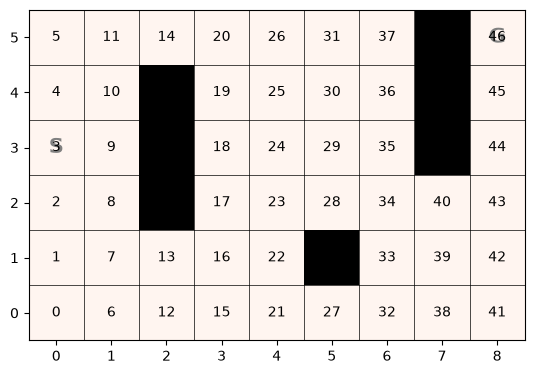

In [5]:
env.image()

## Optimal Policy

This environment has model access, so we can for comparison use value iteration to find the optimal policy.

Note: This maze uses a discount factor of 0.95 to find the shortest path. Otherwise, the value function would be 1 for every state.

Value Iteration: 14it [00:00, 351.32it/s]


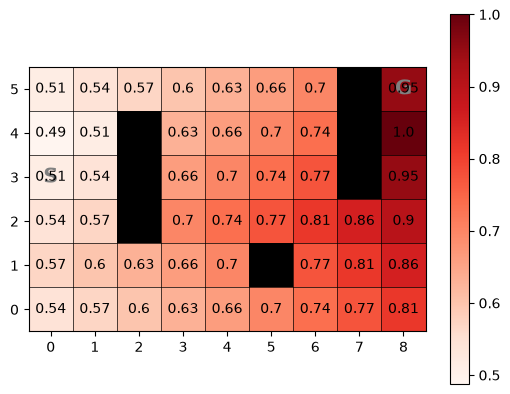

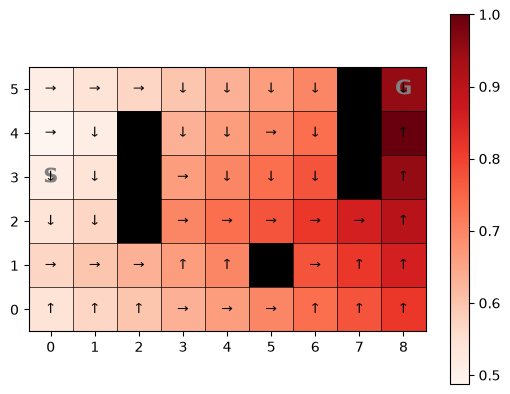

In [6]:
from gym_classics2.algorithms.dynamic_programming import value_iteration
from gym_classics2.algorithms.policy import greedy_policy

V_star = value_iteration(env, discount=.95)
policy_star = greedy_policy(V_star, env, discount=.95, rng=rng)

env.image(V_star, labels=True)
env.image(V_star, policy=policy_star)

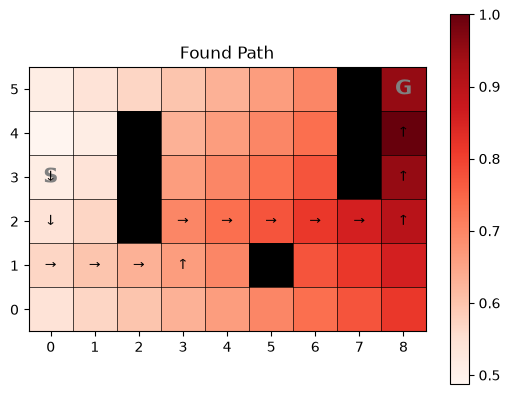

In [7]:
from gym_classics2.algorithms.monte_carlo_methods import sample_episode

path = sample_episode(env, policy=policy_star, max_len=100)
env.image(V=V_star, policy=policy_star, episode=path, title='Found Path')

## Dyna
![Algorithm: Dyna](https://raw.githubusercontent.com/mhahsler/Introduction_to_Reinforcement_Learning/refs/heads/main/figures/RL-Intro_Alg_Dyna.png)

In [8]:
from tqdm import tqdm

# np.argmax does not break ties randomly
def random_argmax(x, rng):
    return rng.choice(np.where(x == np.max(x))[0])

def Dyna(env, discount, alpha, epsilon, n=100, n_planning=5, verbose=False, rng=None):
    rng = np.random.default_rng(rng)
    Q = np.zeros((len(env.states()), len(env.actions())))
    model = {}
    
    for i in tqdm(range(n), desc="Dyna", disable=verbose):
        
        # Learning: Q-Learning using the Environment
        s, r = env.reset()
          
        done = False
        while not done:
            # epsilon-greedy choice w.r.t. Q 
            if rng.random() > epsilon:
                a = random_argmax(Q[s,:], rng)
            else:
                a = rng.integers(env.action_space.n)
            
            sp, r, done, _, _ = env.step(a)
        
            # update deterministic model of the environment
            model[(s, a)] = (sp, r)
        
            Q[s,a] = Q[s,a] + alpha * (r + discount * np.max(Q[sp,:]) - Q[s,a])
            
            s = sp
        
            # Planning: Q-Learning using the Model
            for _ in range(n_planning):
                # sample a previously observed state-action pair
                (s2, a2) = rng.choice(list(model.keys()))
                sp2, r2 = model[(s2, a2)]     
                Q[s2,a2] = Q[s2,a2] + alpha * (r2 + discount * np.max(Q[sp2,:]) - Q[s2,a2])
 
            
    return Q, model

### No Planning

Run Q-Learning over three episodes without planning.

In [9]:
Q, model = Dyna(env, discount=.95, alpha=.1, epsilon=.1, n=3, n_planning=0, rng=rng)

Dyna: 100%|██████████| 3/3 [00:00<00:00, 37.72it/s]


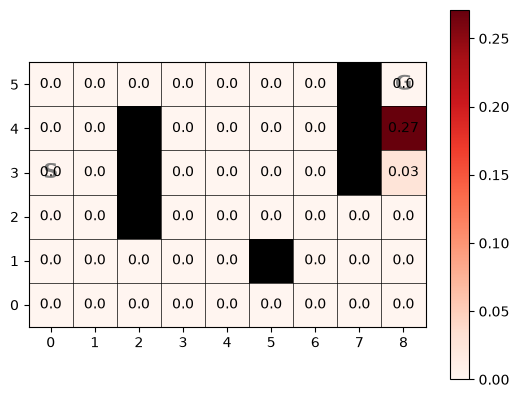

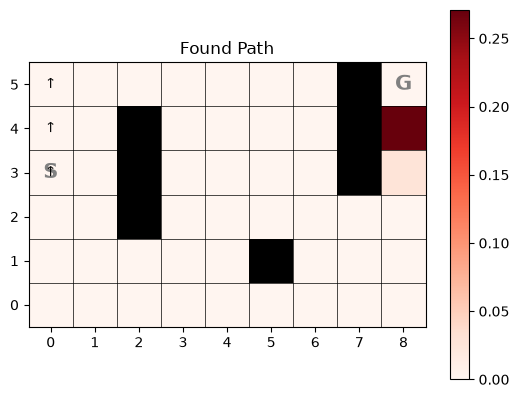

In [10]:
policy = np.argmax(Q, axis=1)
V = np.max(Q, axis = 1)

env.image(V, labels = True)
path = sample_episode(env, policy=policy, max_len=100)
env.image(V=V, policy=policy, episode=path, title='Found Path')

### With Planning Steps

Run Q-learning for three episodes, but at each step perform 50 planning updates using the current model of the environment. 

In [11]:
Q, model = Dyna(env, discount=.95, alpha=.1, epsilon=.1, n=3, n_planning=50, rng=rng)

Dyna: 100%|██████████| 3/3 [00:02<00:00,  1.18it/s]


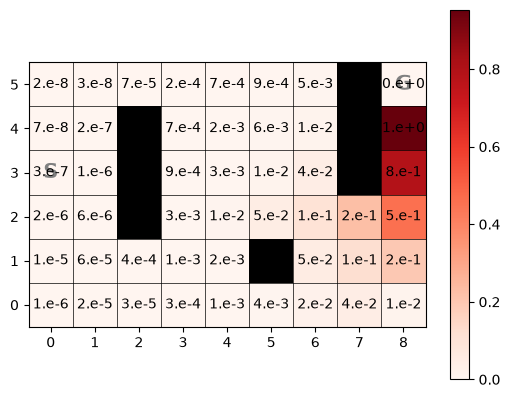

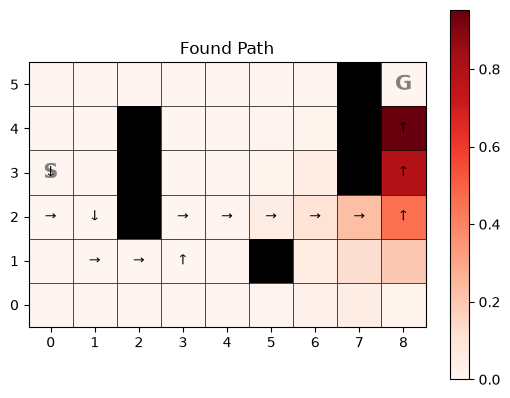

In [12]:
policy = np.argmax(Q, axis=1)
V = np.max(Q, axis = 1)

env.image(V, labels = np.vectorize(lambda x: np.format_float_scientific(x, precision=0, exp_digits=1))(V))

path = sample_episode(env, policy=policy, max_len=100)
env.image(V=V, policy=policy, episode=path, title='Found Path')

In this small maze, it needs at least 3 episodes. The first two are mostly exploration and the model is not good enough yet to provide much help. After episode 3, the learning fine-tunes the solution. 

## Redefining the Reward Structure

We use no discounting, no goal reward and a step cost of 1.

In [13]:
gym_env = gym.make('DynaMaze-v0', tabular = True, goal_reward = 1, step_reward = -0.0001)
env = gym_env.unwrapped
env.reset(seed=SEED)

(3, {})

In [14]:
Q, model = Dyna(env, discount=1, alpha=.1, epsilon=.1, n=3, n_planning=50, rng=rng)

Dyna: 100%|██████████| 3/3 [00:02<00:00,  1.44it/s]


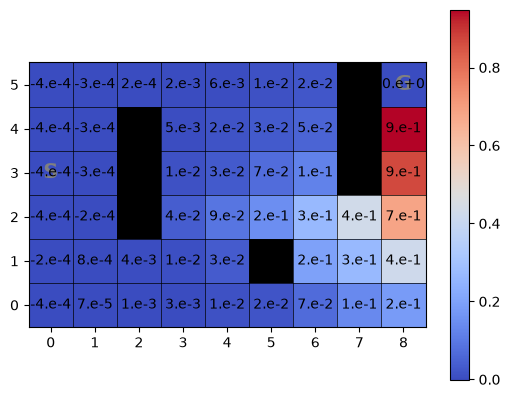

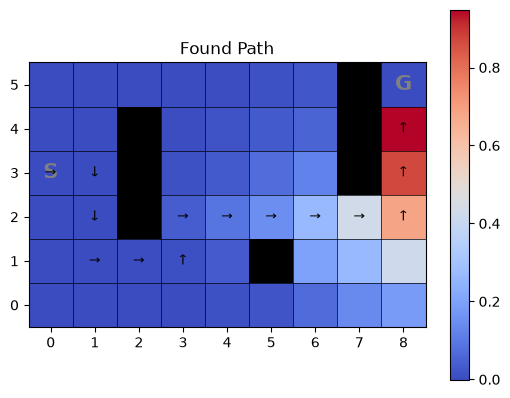

In [15]:
policy = np.argmax(Q, axis=1)
V = np.max(Q, axis = 1)

env.image(V, labels = np.vectorize(lambda x: np.format_float_scientific(x, precision=0, exp_digits=1))(V))

path = sample_episode(env, policy=policy, max_len=100)
env.image(V=V, policy=policy, episode=path, title='Found Path')


&copy; 2025 [Michael Hahsler](https://michael.hahsler.net). 
This work is openly licensed under [Creative Commons Attribution-ShareAlike 4.0 International (CC BY-SA 4.0) License](https://creativecommons.org/licenses/by-sa/4.0/)

![CC BY-SA 4.0](https://licensebuttons.net/l/by-sa/3.0/88x31.png)